In [ ]:

import sys

print("Python is working!")
print("Python version:", sys.version)

Python is working!
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
NumPy version: 2.1.3
Libraries imported successfully!


In [ ]:

import tensorflow_datasets as tfds

print("TensorFlow Datasets imported successfully!")

TensorFlow Datasets imported successfully!


In [ ]:

dataset, dataset_info = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", dataset_info.splits["train"].num_examples)
print("Flower classes:", dataset_info.features["label"].names)

ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:

%pip install importlib_resources

In [ ]:

dataset, dataset_info = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", dataset_info.splits["train"].num_examples)
print("Flower classes:", dataset_info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.GVSMQ5_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Total images: 3670
Flower classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


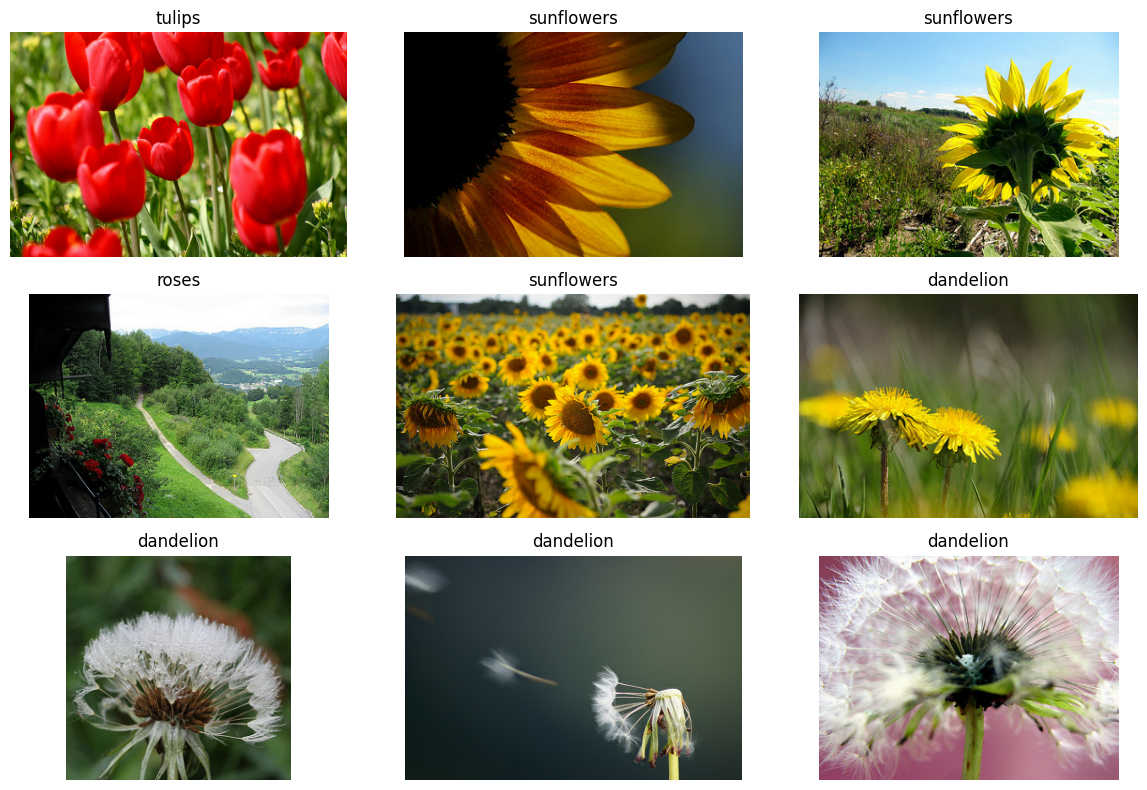

In [ ]:

import matplotlib.pyplot as plt

class_names = dataset_info.features["label"].names

plt.figure(figsize=(12, 8))

for i, (image, label) in enumerate(dataset.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[label.numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

class_counts = np.zeros(len(class_names), dtype=int)

for image, label in dataset:
    class_counts[label.numpy()] += 1

print("Flower Class Distribution")
print("-------------------------")

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count} images")

print("Total images:", class_counts.sum())

Flower Class Distribution
-------------------------
dandelion: 898 images
daisy: 633 images
tulips: 799 images
sunflowers: 699 images
roses: 641 images
Total images: 3670


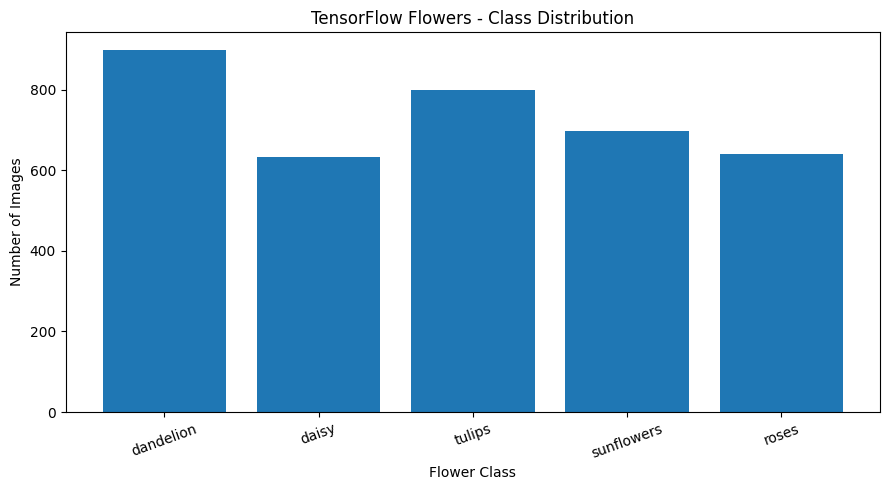

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(class_names, class_counts)

plt.title("TensorFlow Flowers - Class Distribution")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:

# Check the size of 5 flower images

for image, label in dataset.take(5):
    print(
        "Flower:", class_names[label.numpy()],
        "| Image shape:", image.shape
    )

Flower: tulips | Image shape: (333, 500, 3)
Flower: sunflowers | Image shape: (212, 320, 3)
Flower: sunflowers | Image shape: (240, 320, 3)
Flower: roses | Image shape: (240, 320, 3)
Flower: sunflowers | Image shape: (317, 500, 3)


In [ ]:

# Split the dataset into training, validation, and testing sets

(train_dataset, validation_dataset, test_dataset), split_info = tfds.load(
    "tf_flowers",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

print("Training images:", len(list(train_dataset)))
print("Validation images:", len(list(validation_dataset)))
print("Testing images:", len(list(test_dataset)))

Training images: 2569
Validation images: 551
Testing images: 550


In [ ]:

IMG_SIZE = 180
BATCH_SIZE = 32

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

train_dataset = train_dataset.map(preprocess_image)
validation_dataset = validation_dataset.map(preprocess_image)
test_dataset = test_dataset.map(preprocess_image)

train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Image resizing and normalization completed!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image resizing and normalization completed!
Image size: 180 x 180
Batch size: 32


In [ ]:

# Check one batch of training images

for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 180, 180, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:

# Build FloraCoders' first CNN model

num_classes = len(class_names)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Train the FloraCoders CNN model

EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 184s 2s/step - accuracy: 0.4185 - loss: 1.3309 - val_accuracy: 0.5390 - val_loss: 1.1284
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 205s 2s/step - accuracy: 0.5944 - loss: 1.0370 - val_accuracy: 0.5808 - val_loss: 1.0032
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 180s 2s/step - accuracy: 0.6625 - loss: 0.9035 - val_accuracy: 0.6497 - val_loss: 0.9333
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.7166 - loss: 0.7438 - val_accuracy: 0.6534 - val_loss: 0.9274
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.7844 - loss: 0.5924 - val_accuracy: 0.6588 - val_loss: 0.9607
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - accuracy: 0.8322 - loss: 0.4697 - val_accuracy: 0.6171 - val_loss: 1.1676
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 182s 2s/step - accuracy: 0.8817 - loss: 0.3463 - val_accuracy: 0.6407 - val_loss: 1.3242
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.9081 - loss: 0.2692 - val_accuracy: 0.6062 - v

In [ ]:

# Evaluate the baseline model on unseen test images

test_loss, test_accuracy = model.evaluate(test_dataset)

print("\nFloraCoders Baseline Model Results")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 672ms/step - accuracy: 0.6455 - loss: 1.9662

FloraCoders Baseline Model Results
Test Accuracy: 64.55 %
Test Loss: 1.9662


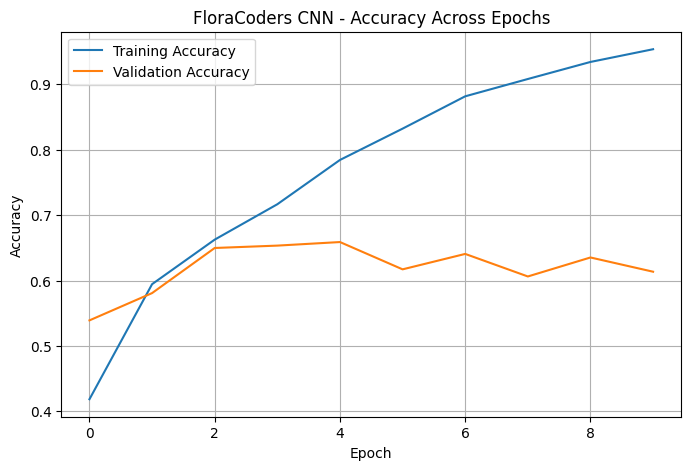

In [ ]:

# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("FloraCoders CNN - Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

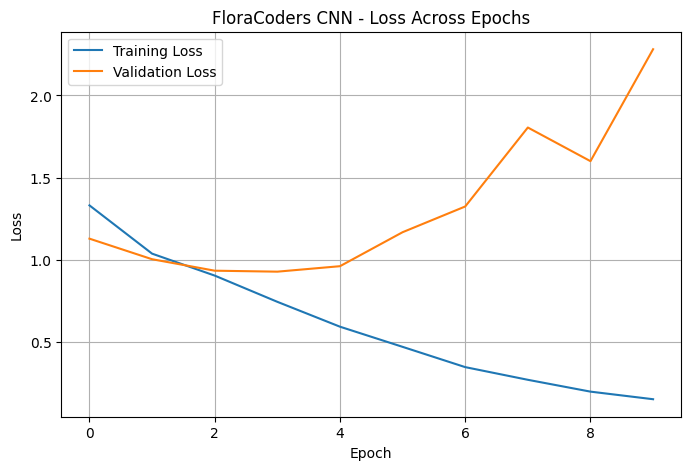

In [ ]:

# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("FloraCoders CNN - Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

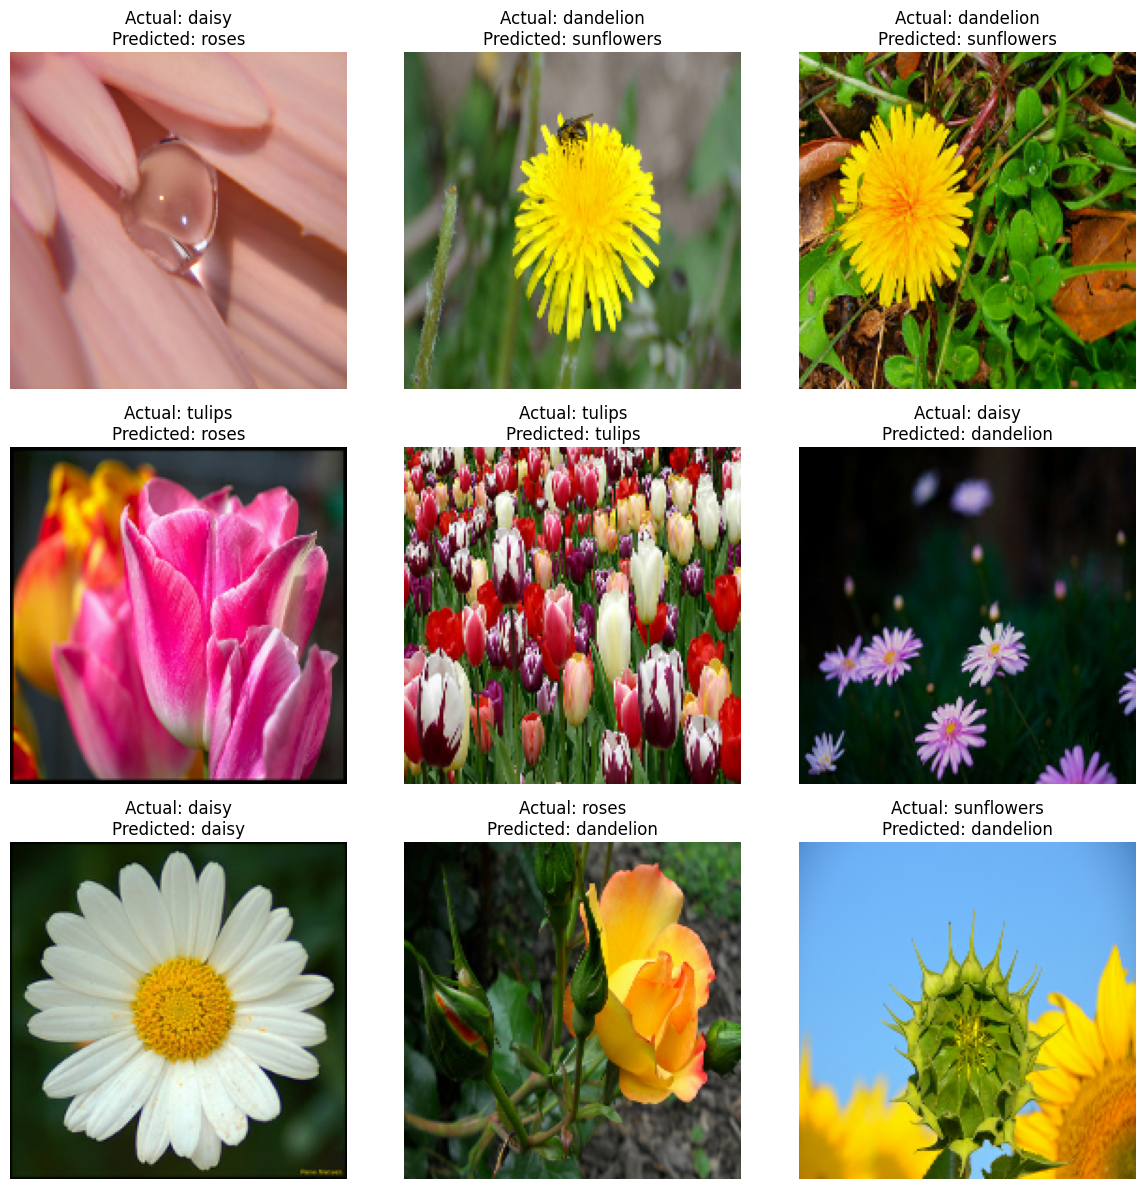

In [ ]:

# Display 9 test images with actual and predicted labels

plt.figure(figsize=(12, 12))

for images, labels in test_dataset.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(9):
        actual_label = int(labels[i].numpy())
        predicted_label = int(np.argmax(predictions[i]))

        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(
            f"Actual: {class_names[actual_label]}\n"
            f"Predicted: {class_names[predicted_label]}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

# Save the trained FloraCoders model

model.save("floracoders_flower_model.keras")

print("FloraCoders model saved successfully!")


FloraCoders model saved successfully!


In [ ]:

import os

print(
    "Saved model exists:",
    os.path.exists("/content/floracoders_flower_model.keras")
)


Saved model exists: True


In [ ]:

from google.colab import drive
import os
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Create a folder for FloraCoders
folder = "/content/drive/MyDrive/FloraCoders"
os.makedirs(folder, exist_ok=True)

# Copy the trained model to Google Drive
source = "/content/floracoders_flower_model.keras"
destination = folder + "/floracoders_flower_model.keras"

shutil.copy2(source, destination)

print("Model backup saved to Google Drive!")
print("File exists:", os.path.exists(destination))


Mounted at /content/drive
Model backup saved to Google Drive!
File exists: True


In [ ]:

import tensorflow as tf
model_path = "/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras"

saved_model = tf.keras.models.load_model(model_path)

print("FloraCoders model loaded successfully!")
saved_model.summary()


FloraCoders model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,201 (8.69 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 12,812 (50.05 KB)

In [ ]:

# Select one batch of test images
images, labels = next(iter(test_dataset))

# Predict using our saved model
predictions = saved_model.predict(images[:1], verbose=0)

# Get the predicted flower class
predicted_index = predictions[0].argmax()
actual_index = int(labels[0].numpy())

print("Predicted flower:", class_names[predicted_index])
print("Actual flower:", class_names[actual_index])
print("Prediction confidence:", f"{predictions[0][predicted_index] * 100:.2f}%")


Predicted flower: roses
Actual flower: daisy
Prediction confidence: 73.44%


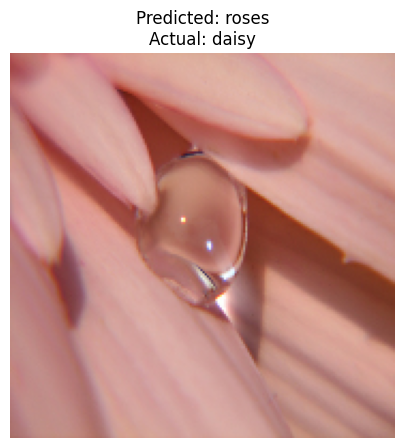

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(images[0].numpy())

plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_index]}"
)

plt.axis("off")
plt.show()


In [ ]:

test_loss, test_accuracy = saved_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


18/18 ━━━━━━━━━━━━━━━━━━━━ 15s 721ms/step - accuracy: 0.6455 - loss: 1.9662
Test Accuracy: 64.55%
Test Loss: 1.9662


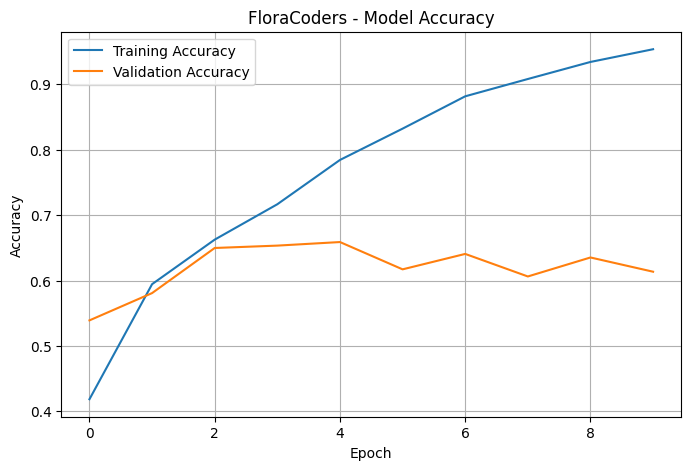

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("FloraCoders - Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


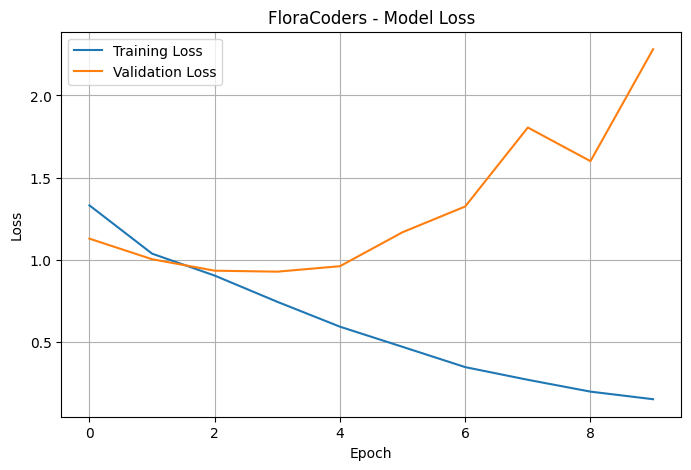

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("FloraCoders - Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]

print("FloraCoders flower classes:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")


FloraCoders flower classes:
0: dandelion
1: daisy
2: tulips
3: sunflowers
4: roses


In [ ]:

import numpy as np
from PIL import Image

def predict_flower(image_path):
    # Open the selected flower image
    image = Image.open(image_path).convert("RGB")

    # Resize it to the model's required size
    image = image.resize((180, 180))

    # Convert image to an array and normalize pixel values
    image_array = np.array(image, dtype=np.float32) / 255.0

    # Add a batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict the flower class
    predictions = saved_model.predict(image_array, verbose=0)
    predicted_index = int(np.argmax(predictions[0]))

    flower_name = class_names[predicted_index]
    confidence = float(predictions[0][predicted_index]) * 100

    return flower_name, confidence

print("FloraCoders prediction function is ready!")


FloraCoders prediction function is ready!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving daisyy.jpg to daisyy (1).jpg


In [ ]:

image_path = next(iter(uploaded.keys()))

flower_name, confidence = predict_flower(image_path)

print("Predicted flower:", flower_name)
print(f"Confidence: {confidence:.2f}%")


Predicted flower: daisy
Confidence: 91.45%


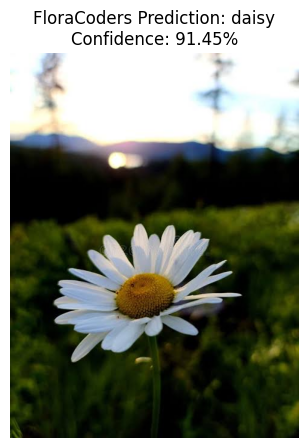

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(
    f"FloraCoders Prediction: {flower_name}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()


In [ ]:

%pip -q install gradio


In [ ]:

import gradio as gr

def classify_flower(image):
    if image is None:
        return "Please upload a flower image.", {}

    # Prepare the uploaded image
    image = Image.fromarray(image).convert("RGB")
    image = image.resize((180, 180))

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    # Get predictions for all five flower classes
    predictions = saved_model.predict(image_array, verbose=0)[0]

    # Show each class with its confidence
    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return max(results, key=results.get), results

print("FloraCoders application function is ready!")


FloraCoders application function is ready!


In [ ]:

app = gr.Interface(
    fn=classify_flower,
    inputs=gr.Image(type="numpy", label="Upload a Flower Picture"),
    outputs=[
        gr.Label(label="Predicted Flower"),
        gr.Label(label="Confidence Scores")
    ],
    title="🌸 FloraCoders - Flower Species Classification",
    description=(
        "Upload a flower image to identify whether it is a "
        "Daisy, Dandelion, Tulip, Sunflower, or Rose."
    )
)

print("FloraCoders app interface created successfully!")


NameError: name 'classify_flower' is not defined

In [ ]:

app.launch(share=True, debug=False)


NameError: name 'app' is not defined

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

model_path = "/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras"

print("Model file exists:", os.path.exists(model_path))
print("FloraCoders folder exists:", os.path.exists("/content/drive/MyDrive/FloraCoders"))


Model file exists: True
FloraCoders folder exists: True


In [ ]:

import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

print("Imports are ready!")


Imports are ready!


In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# Load our best saved model
model_path = "/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras"
saved_model = tf.keras.models.load_model(model_path)

# Flower names in the correct dataset order
class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]

# Function to classify an uploaded flower image
def classify_flower(image):
    if image is None:
        return "Please upload a flower image.", {}

    image = Image.fromarray(image).convert("RGB")
    image = image.resize((180, 180))

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = saved_model.predict(image_array, verbose=0)[0]

    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return max(results, key=results.get), results

print("FloraCoders model and classification function are ready!")

ValueError: File not found: filepath=/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

folder_path = "/content/drive/MyDrive/FloraCoders"

print("Folder exists:", os.path.exists(folder_path))

if os.path.exists(folder_path):
    print("Files inside the folder:")
    print(os.listdir(folder_path))

Folder exists: True
Files inside the folder:
['floracoders_flower_model.keras', 'floracoders_best_model.keras']


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras"

saved_model = tf.keras.models.load_model(model_path)

print("FloraCoders best model loaded successfully!")

FloraCoders best model loaded successfully!


In [ ]:
import numpy as np
from PIL import Image

class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]

def classify_flower(image):
    if image is None:
        return "Please upload a flower image.", {}

    image = Image.fromarray(image).convert("RGB")
    image = image.resize((180, 180))

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = saved_model.predict(image_array, verbose=0)[0]

    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return max(results, key=results.get), results

print("Flower classification function is ready!")

Flower classification function is ready!


In [ ]:
import gradio as gr

app = gr.Interface(
    fn=classify_flower,
    inputs=gr.Image(type="numpy", label="Upload a Flower Picture"),
    outputs=[
        gr.Label(label="Predicted Flower"),
        gr.Label(label="Confidence Scores")
    ],
    title="🌸 FloraCoders - Flower Species Classification",
    description=(
        "Upload a flower image to identify whether it is a "
        "Daisy, Dandelion, Tulip, Sunflower, or Rose."
    )
)

print("FloraCoders app interface created successfully!")

FloraCoders app interface created successfully!


In [ ]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aaec5f7c01fe81f953.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# FloraCoders: Setup after a runtime reset

import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image
from google.colab import drive

# Connect Google Drive if it is not already connected
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# Load our best trained model
model_path = "/content/drive/MyDrive/FloraCoders/floracoders_best_model.keras"
saved_model = tf.keras.models.load_model(model_path)

# Flower names in the correct dataset order
class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]

# Predict the flower in an uploaded image
def classify_flower(image):
    if image is None:
        return "Please upload a flower image.", {}

    image = Image.fromarray(image).convert("RGB")
    image = image.resize((180, 180))

    image_array = np.array(image, dtype=np.float32) / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    predictions = saved_model.predict(image_array, verbose=0)[0]

    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return max(results, key=results.get), results

# Create the application interface
app = gr.Interface(
    fn=classify_flower,
    inputs=gr.Image(type="numpy", label="Upload a Flower Picture"),
    outputs=[
        gr.Label(label="Predicted Flower"),
        gr.Label(label="Confidence Scores")
    ],
    title="FloraCoders - Flower Species Classification",
    description=(
        "Upload a flower image to identify a daisy, dandelion, "
        "tulip, sunflower, or rose."
    )
)

print("FloraCoders setup completed successfully!")

FloraCoders setup completed successfully!


In [ ]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8c542e798e1b5b734e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
